In [1]:
# Imports
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Variável simbólica
s = sp.symbols('s')

# Parâmetros do circuito
C1, C2, L2, L1, RL, Rs = sp.symbols(
    'C1 C2 L2 L1 RL Rs', positive=True
)

# Exemplo de uma expressão com várias frações
# Zp = (s * L2 * RL) / (s*L2 + RL + s**2*RL*C2*L2)

# Zeq = (s**4*L1*L2*C1*C2*RL + s**3*L1*L2*C1 + s**2*(C1*L2*RL + RL*C2*L2 + C1*L1*RL) + s*L2 + RL) / (s**2*C1*L2 + s*C1*RL + s**3*C1*C2*L2*RL)

Zp = s**2 * L2 * C1
Zeq = s**2*L2*C2*(s**2*L1*C1) + s**2*C1*L1 + 1 + s**2*L2*C1
H = Zp/Zeq

# Combinar as frações numa única expressão
H_simplificada = sp.cancel(H)

# Separar numerador e denominador
numerador, denominador = sp.fraction(H_simplificada)

# Desenvolver os polinómios
numerador = sp.collect(sp.expand(numerador), s)
denominador = sp.collect(sp.expand(denominador), s)



In [3]:
from IPython.display import display, Math

numerador, denominador = sp.fraction(
    sp.cancel(H)
)

display(Math(
    r'N(s) = ' + sp.latex(sp.collect(sp.expand(numerador), s))
))

display(Math(
    r'D(s) = ' + sp.latex(sp.collect(sp.expand(denominador), s))
))

display(Math(
    r'H(s) = \frac{' + sp.latex(numerador) +
    r'}{' + sp.latex(denominador) + r'}'
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
#Dimensionamento

fc = 93e6   #Hz
bw = 20e6  #Hz
L_fixed = 100e-6    #H 
quality = fc/bw



c1 = 1/((2*np.pi*fc)**2 * L_fixed)
l1 = L_fixed
l2 = l1
c2 = c1
print("Value C1",c1)
print("Value C2",c2)
print("Value L1",l1)
print("Value L2",l2)

# c1 = 29.3e-15
# l2 = 8.5e-6
# l1 = 100e-6
# c2 = 345e-15



Value C1 2.9286964863665674e-14
Value C2 2.9286964863665674e-14
Value L1 0.0001
Value L2 0.0001


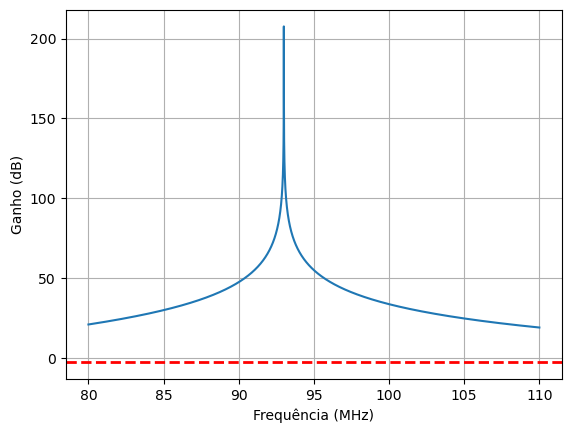

In [5]:
# Variável simbólica da frequência
f = sp.symbols('f', positive=True, real=True)

# Substituir s por j*2*pi*f
H_jw = H_simplificada.subs(s, sp.I * 2 * sp.pi * f)
# Converter a expressão simbólica numa função numérica
H_func = sp.lambdify(f, H_jw, modules='numpy')

# Array de frequências
frequencias = np.linspace(80e6, 110e6, 10000)

valores = {
    C1: c1,
    C2: c2,
    L2: l2,
    L1: l1,
    RL: 50,
}

H_numerica = H_jw.subs(valores)

H_func = sp.lambdify(f, H_numerica, modules="numpy")

H_valores = H_func(frequencias)

ganho_db = 20 * np.log10(np.abs(H_valores))

# Gráfico
plt.plot(frequencias / 1e6, ganho_db)
plt.xlabel("Frequência (MHz)")
plt.ylabel("Ganho (dB)")
plt.axhline(y=-3,color='red',linestyle='--', linewidth=2,)
plt.grid(True)
plt.show()






Polos numéricos:
-584336231.0103542j
584336231.0103542j
-584336236.125049j
584336236.125049j


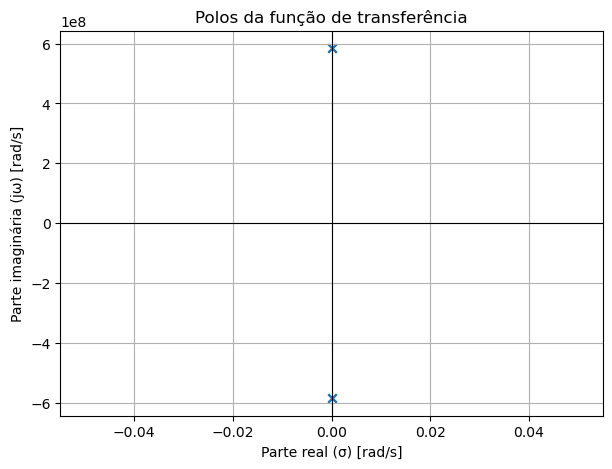

In [6]:
# Polos
H_num = sp.cancel(H.subs(valores))
num, den = sp.fraction(H_num)
polos_num = sp.nroots(den)

print("Polos numéricos:")
for polo in polos_num:
    print(complex(polo))

polos_complexos = np.array([complex(p) for p in polos_num])

plt.figure(figsize=(7, 5))
plt.scatter(polos_complexos.real, polos_complexos.imag, marker='x')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)

plt.xlabel('Parte real (σ) [rad/s]')
plt.ylabel('Parte imaginária (jω) [rad/s]')
plt.title('Polos da função de transferência')
plt.grid(True)
plt.show()

In [7]:
#LC Dimensionamento 

fc = 93e6   #Hz
bw = 20e6  #Hz
L_fixed = 100e-6    #H 
quality = fc/bw


#
s = sp.symbols('s')

# Parâmetros do circuito
C, L,RL, RS = sp.symbols(
    'C L RL RS', positive=True
)

# Exemplo de uma expressão com várias frações
Zp = (s * 1/(C*RS)) 

Zeq = s**2 + s*(2/(C*RL)) + 1/(L*C)

H = (Zp)/Zeq

# Combinar as frações numa única expressão
# H_simplificada = sp.cancel(H)

# Separar numerador e denominador
numerador, denominador = sp.fraction(H)

# Desenvolver os polinómios
numerador = sp.collect(sp.expand(numerador), s)
denominador = sp.collect(sp.expand(denominador), s)



from IPython.display import display, Math

numerador, denominador = sp.fraction(
    H
)

display(Math(
    r'N(s) = ' + sp.latex(sp.collect(sp.expand(numerador), s))
))

display(Math(
    r'D(s) = ' + sp.latex(sp.collect(sp.expand(denominador), s))
))

display(Math(
    r'H(s) = \frac{' + sp.latex(numerador) +
    r'}{' + sp.latex(denominador) + r'}'
))


r = 50
w0 = 2*np.pi*fc
qFactor = w0 / bw
l = 0.37*50e-9
print(l)    
# c = qFactor/(w0*r)
# print(c)
c = 1/(l*w0**2)
c = np.sqrt(2)/r
print(c)
print(20*np.log10(1/2))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

1.85e-08
0.0282842712474619
-6.020599913279624
